# Which stars belong together?
*Galactic archaeology with Gaia and Rubin*  
**Ani Chiti · Ioana Ciucă · Stanford PHYSICS 367**

On Monday, Ani picked out stars in Reticulum II by their colour and brightness, then checked where they fell on the sky. Today we’ll start with motion. If we pick stars that move together, do they also cluster on the sky or line up in a colour–magnitude diagram?

Start with two clusters, the Pleiades and M5. Then take two stars that might belong to the SGP-S stream and look for them in Rubin images using the catalogue of objects measured in those images.

Please remember what we learn in this session will be useful for the upcoming [Gaia DR4 Sprint at KIPAC, December 2–4](https://kipac.stanford.edu/events/kipac-workshops/kipac-gaia-dr4-x-agentic-ai-sprint-decoding-milky-way-stanford)

## Before you start · 5 min

Two stars look close together on the sky. What would you measure to find out whether they might belong to the same cluster? Discuss with your neighbour.

| Gaia column | What it measures |
|---|---|
| `ra`, `dec` | Right ascension and declination in degrees. |
| `phot_g_mean_mag` | Apparent brightness in Gaia’s G band. Smaller magnitudes are brighter. |
| `bp_rp` | Colour (BP − RP). Larger values are redder. |
| `pmra`, `pmdec` | Proper motion in right ascension and declination, in milliarcseconds per year (mas/yr). Gaia includes the cos(dec) factor in `pmra`. |
| `parallax` | The apparent shift in position as Earth orbits the Sun, in milliarcseconds (mas). Nearer stars have larger parallaxes. |

On the Rubin Science Platform, open this notebook with the **LSST** kernel and run the two setup cells. The Gaia downloads come from ESA. Exercise 3 uses the Rubin catalogue through your RSP session.

In [2]:
from pathlib import Path
from astroquery.gaia import Gaia
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table
from IPython.display import display

plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 11, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.grid': False,
    'figure.constrained_layout.use': True,
})
TEAL, ORANGE, GREY = '#007C83', '#C76D33', '#B7BEC5'

data_dir = Path('gaia_data')
data_dir.mkdir(exist_ok=True)

def save_sample(table, query, name):
    path = data_dir / f'{name}.ecsv'
    table.write(path, format='ascii.ecsv', overwrite=True)
    path.with_suffix('.adql').write_text(query, encoding='utf-8')
    print(f'{len(table):,} sources saved to {path}')

In [3]:
from io import BytesIO
import requests

def download_csv(query):
    """Request fresh rows from the public ESA TAP service."""
    endpoint = 'https://gea.esac.esa.int/tap-server/tap/sync'
    parameters = dict(REQUEST='doQuery', LANG='ADQL', FORMAT='csv',
                      MAXREC=100000, QUERY=query)
    response = requests.get(endpoint, params=parameters, timeout=(10, 90))
    response.raise_for_status()
    return Table.read(BytesIO(response.content), format='ascii.csv')

def download_cluster(query):
    """Retrieve a Gaia table and check its size against an archive count."""
    where = query.split('FROM', 1)[1]
    expected = int(download_csv('SELECT COUNT(*) AS n FROM' + where)[0][0])
    try:
        job = Gaia.launch_job_async(query)
        result = job.get_results()
        if len(result) == expected:
            return result
        print(f'Received {len(result):,} of {expected:,} rows. Requesting CSV from ESA.')
    except Exception as error:
        print(f'The asynchronous job failed ({type(error).__name__}). Trying ESA’s CSV endpoint.')
    result = download_csv(query)
    if len(result) != expected:
        raise RuntimeError(f'Incomplete download: {len(result):,} of {expected:,} rows. Rerun this cell.')
    return result

## 1. The Pleiades · 10 min

This query takes stars within 1° of the star called Alcyone (definitely google it!), in the Pleiades. We want stars brighter than G = 20 with a measured colour and proper motion, a good astrometric fit, and a parallax uncertainty below 10%.

Find the sky radius and the parallax cut in the query. Then run it and look at the first five stars. 

Here is the official [ESA’s Pleiades tutorial](https://github.com/esa/gaia-jupyter-notebooks/blob/main/data-release-3-tutorials/tutorial_use_case_pleiades.ipynb) -- please have a look!

In [5]:
query = """
SELECT source_id, ra, dec, pmra, pmdec, phot_g_mean_mag, bp_rp
FROM gaiadr3.gaia_source
WHERE 1=CONTAINS(POINT('ICRS', ra, dec), CIRCLE('ICRS', 56.87125, 24.10493, 1.0))
  AND ruwe < 1.4
  AND parallax_over_error > 10
  AND phot_g_mean_mag < 20.0
  AND bp_rp IS NOT NULL
  AND pmra IS NOT NULL
  AND pmdec IS NOT NULL
"""
pleiades = download_cluster(query)
save_sample(pleiades, query, "pleiades_dr3")
display(pleiades[:5])

HTTPError: 429 Client Error: 429 for url: https://gea.esac.esa.int/tap-server/tap/sync?REQUEST=doQuery&LANG=ADQL&FORMAT=csv&MAXREC=100000&QUERY=SELECT+COUNT%28%2A%29+AS+n+FROM+gaiadr3.gaia_source%0AWHERE+1%3DCONTAINS%28POINT%28%27ICRS%27%2C+ra%2C+dec%29%2C+CIRCLE%28%27ICRS%27%2C+56.87125%2C+24.10493%2C+1.0%29%29%0A++AND+ruwe+%3C+1.4%0A++AND+parallax_over_error+%3E+10%0A++AND+phot_g_mean_mag+%3C+20.0%0A++AND+bp_rp+IS+NOT+NULL%0A++AND+pmra+IS+NOT+NULL%0A++AND+pmdec+IS+NOT+NULL%0A

### Select stars by proper motion

The circle on the left is centred on the Pleiades’ motion, (20, −45) mas/yr. The colour–magnitude diagram (CMD) on the right shows the stars inside that circle in teal. Brighter stars are at the top.

Run the cell with `radius_pm = 3.0`, then try 6.0 mas/yr. Where do the extra stars fall in the CMD?

In [ ]:
radius_pm = 3.0  # mas/yr
offset = np.hypot(pleiades['pmra'] - 20, pleiades['pmdec'] + 45)
selected = pleiades[offset < radius_pm]
print(f'{len(selected):,} Pleiades candidates')

fig, (ax_pm, ax_cmd) = plt.subplots(1, 2, figsize=(10, 4.4))
for table, colour, label in [(pleiades, GREY, 'Downloaded field'),
                             (selected, TEAL, 'Motion-selected')]:
    ax_pm.scatter(table['pmra'], table['pmdec'], s=7, color=colour, alpha=.65)
    ax_cmd.scatter(table['bp_rp'], table['phot_g_mean_mag'], s=7,
                   color=colour, alpha=.65, label=label)
ax_pm.add_patch(plt.Circle((20, -45), radius_pm, fill=False, color=ORANGE))
ax_pm.set(xlim=(-55, 60), ylim=(-85, 30), aspect='equal',
          xlabel='μα* [mas/yr]', ylabel='μδ [mas/yr]', title='Proper motion')
ax_cmd.invert_yaxis()
ax_cmd.set(xlabel='Gaia BP − RP [mag]', ylabel='Apparent G [mag]', title='Colour–magnitude diagram')
ax_cmd.legend(fontsize=8)
plt.show()

## 2. Find M5 · 15 min

M5 is much farther away than the Pleiades. What would happen to its stars if you kept the same parallax cut?

Compare this query with the first one, then run it. It takes a random subset of stars within 0.6° of M5, down to G = 20. The BP and RP cuts select stars with well-measured colours.

In [ ]:
query = """
SELECT source_id, ra, dec, pmra, pmdec, phot_g_mean_mag, bp_rp
FROM gaiadr3.gaia_source
WHERE 1=CONTAINS(POINT('ICRS', ra, dec), CIRCLE('ICRS', 229.6384, 2.081, 0.6))
  AND ruwe < 1.4
  AND phot_bp_mean_flux_over_error > 10
  AND phot_rp_mean_flux_over_error > 10
  AND random_index < 300000000
  AND phot_g_mean_mag < 20.0
  AND bp_rp IS NOT NULL
  AND pmra IS NOT NULL
  AND pmdec IS NOT NULL
"""
stars = download_cluster(query)
save_sample(stars, query, "m5_dr3")
display(stars[:5])

### Estimate M5’s proper motion

Each hexagon counts stars with similar proper motions. Find the clump and read its centre off the axes. Write down both numbers, including their signs.

My estimate of (μα*, μδ) is (___, ___) mas/yr.

In [ ]:
fig, ax = plt.subplots(figsize=(6.4, 5))
h = ax.hexbin(stars['pmra'], stars['pmdec'], gridsize=110, mincnt=1,
              bins='log', extent=(-15, 15, -25, 10), cmap='viridis')
fig.colorbar(h, ax=ax, label='Sources per hexagon')
ax.set(xlim=(-15, 15), ylim=(-25, 10), xlabel='μα* [mas yr⁻¹]',
       ylabel='μδ [mas yr⁻¹]', title='Proper motions near M5')
plt.show()

Enter your estimate below. A star lies 0.6 mas/yr from your centre along one axis and 0.8 mas/yr along the other. Would you include it with a radius of 0.75 mas/yr? What about 2.0 mas/yr?

Try both radii. Look at the teal stars in the sky map and the CMD. What evidence do you see that they belong to M5?

In [ ]:
pmra_c, pmdec_c = 4.0, -10.0  # Replace with your reading of the clump centre.
radius_pm = 0.75              # Widen to 2.0 mas/yr, then compare the outer panels.
delta_pm = np.hypot(stars['pmra'] - pmra_c, stars['pmdec'] - pmdec_c)
member = delta_pm < radius_pm
candidates = stars[member]
print(f'{len(candidates):,} / {len(stars):,} stars selected as M5 candidates')

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
views = [('ra', 'dec', 'RA [deg]', 'Dec [deg]', 'Sky position'),
         ('pmra', 'pmdec', 'μα* [mas yr⁻¹]', 'μδ [mas yr⁻¹]', 'Proper motion'),
         ('bp_rp', 'phot_g_mean_mag', 'BP − RP [mag]', 'Apparent G [mag]',
          'Colour–magnitude diagram')]
for ax, (x, y, xlabel, ylabel, title) in zip(axes, views):
    ax.scatter(stars[x], stars[y], s=2, color=GREY, alpha=.35, rasterized=True)
    ax.scatter(candidates[x], candidates[y], s=3, color=TEAL, alpha=.5,
               label='Motion-selected candidates', rasterized=True)
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
axes[0].set_aspect(1 / np.cos(np.deg2rad(2.081)))
axes[0].legend(loc="upper right", fontsize=8, markerscale=2)
axes[1].add_patch(plt.Circle((pmra_c, pmdec_c), radius_pm,
                             fill=False, color=ORANGE, lw=1.5))
axes[1].set(xlim=(-15, 15), ylim=(-25, 10))
axes[2].set(xlim=(-.4, 3.2), ylim=(20.2, 10))
fig.savefig('m5_membership.png', dpi=180, bbox_inches='tight')
plt.show()

Which radius would you keep? Point to one feature in the sky map or the CMD that helped you decide.

## 3. Find two stream stars in Rubin · 25 min

SGP-S is a thin stream of stars about 9.5 kpc from the Sun. Yang and colleagues traced it over 58° using Gaia colours and proper motions. A short stretch crosses ELAIS-S1, a field Rubin imaged repeatedly. We’ll work in a circle just 0.3° across. [SGP-S discovery paper](https://arxiv.org/abs/2208.05176) · [Rubin’s ELAIS-S1 depth map, Figure 6](https://dp2.lsst.io/tutorials/notebook/301/notebook-301-3.html#depth-and-deep-coadd-plots)

Two stars in this field are published SGP-S candidates. Their Gaia IDs are given below. Start by finding them on a proper-motion plot of all the Gaia stars in the field. How closely do the two motions agree compared with the rest of the field? [Published candidate list](https://github.com/abonaca/streams_overview/blob/2663cc06e5ced4b02850de15140bc9f136f3341b/data/members/streams/SGP-S.fits)

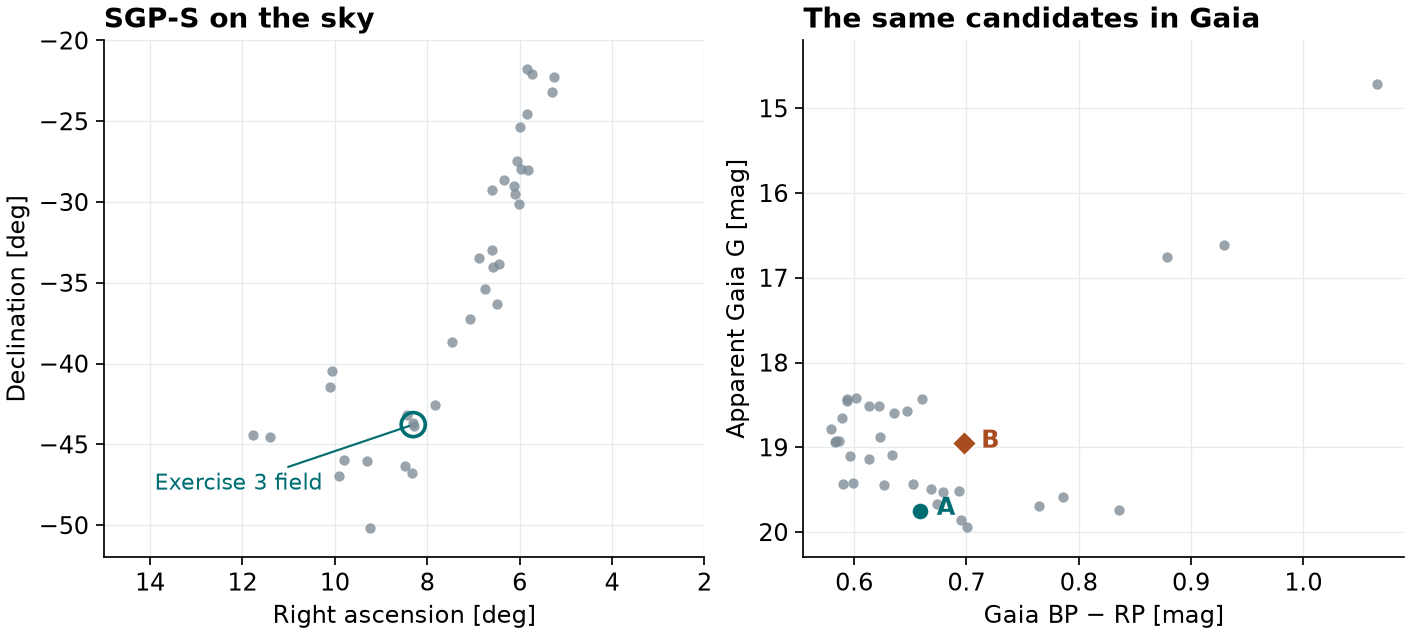

Each grey point is a published SGP-S candidate. The circle marks our field, enlarged so you can see it. **A** and **B** follow the order of the two Gaia IDs below. Which star looks brighter? Which is bluer?

In [ ]:
from astropy.coordinates import SkyCoord
import astropy.units as u
from lsst.rsp import get_tap_service

field_ra, field_dec = 8.303, -43.776  # degrees
target_ids = [4980391162444934656, 4980409235667391360]  # Gaia DR3 integer IDs

gaia_query = f"""
SELECT source_id, ra, dec, pmra, pmdec, pmra_error, pmdec_error, phot_g_mean_mag
FROM gaiadr3.gaia_source
WHERE 1 = CONTAINS(POINT('ICRS', ra, dec),
                   CIRCLE('ICRS', {field_ra}, {field_dec}, 0.15))
  AND pmra IS NOT NULL AND pmdec IS NOT NULL
"""
gaia_field = download_csv(gaia_query)
save_sample(gaia_field, gaia_query, 'sgps_gaia_dr3')
if not set(target_ids).issubset(gaia_field['source_id']):
    raise ValueError('The Gaia download is missing a target. Rerun this cell before matching.')

Write your selection and plot below. Use the full integer IDs to select the two rows. The columns `pmra_error` and `pmdec_error` give the uncertainties in mas/yr.

In [ ]:
# Select the two Gaia candidates and mark them on your proper-motion plot.

### Which Rubin object goes with each Gaia star?

Run the cell below. It reads the DP2 Object catalogue made from stacked Rubin images. The Rubin search extends a little past the Gaia field so you can still find neighbours near the edge. We keep objects brighter than *r* = 22.

In [ ]:
rubin_query = f"""
SELECT objectId, coord_ra, coord_dec, g_psfMag, r_psfMag
FROM dp2.Object
WHERE CONTAINS(POINT('ICRS', coord_ra, coord_dec),
               CIRCLE('ICRS', {field_ra}, {field_dec}, 0.16)) = 1
  AND r_psfMag < 22
"""
rubin_field = get_tap_service('tap').search(rubin_query, maxrec=100000).to_table()
if not len(rubin_field):
    raise ValueError('The Rubin query returned no objects. Check the field centre and the DP2 table.')
if len(rubin_field) == 100000:
    raise ValueError('The Rubin query reached the row limit. Check completeness before matching.')
print(f'{len(rubin_field):,} Rubin objects')
display(rubin_field[:3])

Write the match yourself. For each Gaia candidate, measure the angular separation to the Rubin objects. Both catalogues give RA and Dec in degrees. `SkyCoord.separation` measures angles on the sky.

Make a two-row table. For each Gaia ID, report how many Rubin objects lie within **1 arcsec**. If exactly one does, give its `objectId`, separation in arcsec and *r* magnitude. Label an empty circle “no match” and a circle with several objects “ambiguous”.

Pick one row to explain to your neighbour. What observation supports the identification across catalogues? What measurement would help you decide whether this star belongs to SGP-S?

For the figure below, put each unique pair in `rubin_ids` using the integer Gaia ID as the key and the integer Rubin ID as the value. Leave out any target whose identification is uncertain.

In [ ]:
rubin_ids = {}
# Measure the separations, make your two-row table, and record the unique pairs.

### Put your matches on the sky and the CMD

Run the next cell after you fill in `rubin_ids`. On the sky map, an outline marks each Gaia target and a plus marks its Rubin counterpart. On the CMD, compare your matches to the other Rubin objects with measured *g* and *r*. Which target is brighter in *r*? Does the colour ordering agree with the Gaia diagram above?

In [ ]:
g_mag = np.ma.asarray(rubin_field['g_psfMag'], dtype=float).filled(np.nan)
r_mag = np.ma.asarray(rubin_field['r_psfMag'], dtype=float).filled(np.nan)
has_colour = np.isfinite(g_mag) & np.isfinite(r_mag)
fig, (sky, cmd) = plt.subplots(1, 2, figsize=(10, 4.6))
sky.scatter(rubin_field['coord_ra'], rubin_field['coord_dec'], s=4, color=GREY, alpha=.45)
cmd.scatter((g_mag - r_mag)[has_colour], r_mag[has_colour], s=4, color=GREY, alpha=.45)

for gaia_id, label, colour, marker in zip(target_ids, 'AB', [TEAL, ORANGE], ['o', 'D']):
    star = gaia_field[gaia_field['source_id'] == gaia_id][0]
    sky.scatter(star['ra'], star['dec'], marker=marker, s=110, facecolors='none',
                edgecolors=colour, linewidths=1.7)
    sky.annotate(label, (star['ra'], star['dec']), xytext=(9, 3),
                 textcoords='offset points', color=colour, weight='bold')
    if gaia_id not in rubin_ids:
        continue
    idx, = np.flatnonzero(rubin_field['objectId'] == rubin_ids[gaia_id])
    sky.scatter(rubin_field['coord_ra'][idx], rubin_field['coord_dec'][idx],
                marker='+', s=55, color=colour)
    if has_colour[idx]:
        x, y = g_mag[idx] - r_mag[idx], r_mag[idx]
        cmd.scatter(x, y, marker=marker, s=60, color=colour)
        cmd.annotate(label, (x, y), xytext=(8, 3), textcoords='offset points',
                     color=colour, weight='bold')
    else:
        print(f'{label} has a Rubin counterpart but lacks a usable g − r colour.')

sky.set(xlabel='RA [deg]', ylabel='Dec [deg]', title='Gaia targets in the Rubin field')
sky.set_aspect(1 / np.cos(np.deg2rad(field_dec)))
sky.invert_xaxis()
cmd.set(xlabel='Rubin g − r [mag]', ylabel='Apparent r [mag]', title='Rubin colour–magnitude diagram')
cmd.invert_yaxis()
plt.show()

## Optional stretch · How often would you match by chance? · 8 min

Two targets make a small sample. Use **all** the stars in `gaia_field` to test your matching rule. Count how many have exactly one Rubin neighbour within 1 arcsec.

Now move every Gaia position 10 arcsec north and repeat, keeping the Rubin positions fixed. Use the same stars and search radius both times. What fraction of the shifted positions still have a match? What does that tell you about the two identifications above?

If you need a hint, `astropy.coordinates.search_around_sky` returns all pairs inside an angular radius.

In [ ]:
# Compare the original and shifted positions.

## Gaia references

- [Select cluster stars by proper motion](https://github.com/esa/gaia-jupyter-notebooks/blob/main/data-release-3-tutorials/tutorial_use_case_pleiades.ipynb)
- [Check column units and convert them](https://github.com/esa/gaia-jupyter-notebooks/blob/main/data-release-3-tutorials/tutorial_change_units.ipynb)
- [Retrieve spectra and epoch data with DataLink](https://github.com/esa/gaia-jupyter-notebooks/blob/main/data-release-3-tutorials/tutorial_datalink_download.ipynb)
- [ESA notebooks by data release](https://github.com/esa/gaia-jupyter-notebooks)
- [Astroquery Gaia documentation](https://astroquery.readthedocs.io/en/stable/gaia/gaia.html)

For DR4, check the column names, units, reference epoch, and recommended quality cuts. Source identifiers can change between releases. Save the query and release with your results.

### Credits

The cluster exercises adapt ESA’s Pleiades tutorial (v1.2, May 2025). The SGP-S exercise uses Gaia DR3 astrometry and Rubin DP2 Object photometry. The candidate list accompanies Bonaca & Price-Whelan’s [Stellar streams in the Gaia era](https://doi.org/10.1016/j.newar.2024.101713). [Rubin DP2 Object catalogue](https://dp2.lsst.io/products/catalogs/object.html)

ESA and the Gaia Data Processing and Analysis Consortium (DPAC) provided the Gaia data. GPT 6.2 Astra Ultra helped with the notebook. [Gaia data credits](https://www.cosmos.esa.int/web/gaia-users/credits)